In [ ]:
!pip install -q ucimlrepo

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from graphviz import Digraph
from matplotlib.colors import to_hex
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

CRITERION = "gini"
CLASS_WEIGHT = None
DROP_COLS = ["Height", "Weight"]  # columns to drop completely
COLS = ["train_acc", "test_acc", "test_precision", "test_recall", "test_f1"]

ds = fetch_ucirepo(id=544)
y = ds.data.targets.iloc[:, 0]
X = ds.data.features.drop(columns=DROP_COLS)
print("X shape:", X.shape, "| Missing values:", int(X.isnull().sum().sum()),
      "| Duplicate rows:", int(pd.concat([X, y], axis=1).duplicated().sum()))
print("Text columns:", list(X.select_dtypes("object").columns))
print(y.value_counts())
display(X.head())

# accuracy + macro precision/recall/f1
scores = lambda yt, yp: [accuracy_score(yt, yp)] + [
    fn(yt, yp, average="macro", zero_division=0) for fn in (precision_score, recall_score, f1_score)]

def split(drop):
    Xv = pd.get_dummies(ds.data.features.drop(columns=drop), dtype=int)  # text -> numeric
    return train_test_split(Xv, y, test_size=0.2, random_state=42, stratify=y)

def fit(Xtr, ytr, **kw):
    return DecisionTreeClassifier(criterion=CRITERION, class_weight=CLASS_WEIGHT,
                                  random_state=42, **kw).fit(Xtr, ytr)

def sweep(Xtr, Xte, ytr, yte):
    rows = {}
    for d in range(1, fit(Xtr, ytr).get_depth() + 1):
        m = fit(Xtr, ytr, max_depth=d)
        rows[d] = [m.score(Xtr, ytr)] + scores(yte, m.predict(Xte))
    df = pd.DataFrame(rows, index=COLS).T.round(4)
    df.index.name = "depth"
    return df

def evaluate(m, Xte, yte, title, pct=False):
    p, L = m.predict(Xte), m.classes_
    print(classification_report(yte, p, digits=4))
    cm = confusion_matrix(yte, p, labels=L)
    display(pd.DataFrame(cm, index=[f"Actual: {c}" for c in L],
                         columns=[f"Predicted: {c}" for c in L]))
    annot = np.array([[f"{v}" + (f"\n({v / r.sum() * 100:.0f}%)" if pct else "") for v in r] for r in cm])
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, xticklabels=L, yticklabels=L)
    plt.xlabel("Predicted label"); plt.ylabel("True label"); plt.title(title)
    plt.xticks(rotation=45, ha="right"); plt.show()

X shape: (2111, 14) | Missing values: 0 | Duplicate rows: 29
Text columns: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


,Gender,Age,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,Female,21.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation
1,Female,21.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation
2,Male,23.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation
3,Male,27.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking
4,Male,22.0,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation


Depth: 17 | Leaves: 356 | Train acc: 1.0 | Test acc: 0.7423


,train_acc,test_acc,test_precision,test_recall,test_f1
depth,,,,,
1,0.3051,0.3144,0.1069,0.2816,0.1505
2,0.3969,0.3759,0.2219,0.3554,0.2587
3,0.4887,0.4988,0.4690,0.4795,0.4159
4,0.5640,0.5603,0.6095,0.5458,0.5244
5,0.6653,0.6217,0.6632,0.6123,0.6157
6,0.7310,0.6643,0.6861,0.6579,0.6549
7,0.7749,0.6761,0.7105,0.6691,0.6656
8,0.8288,0.6879,0.6949,0.6812,0.6799
9,0.8726,0.7210,0.7293,0.7148,0.7130


Best depth: 16 | Test accuracy: 0.7494


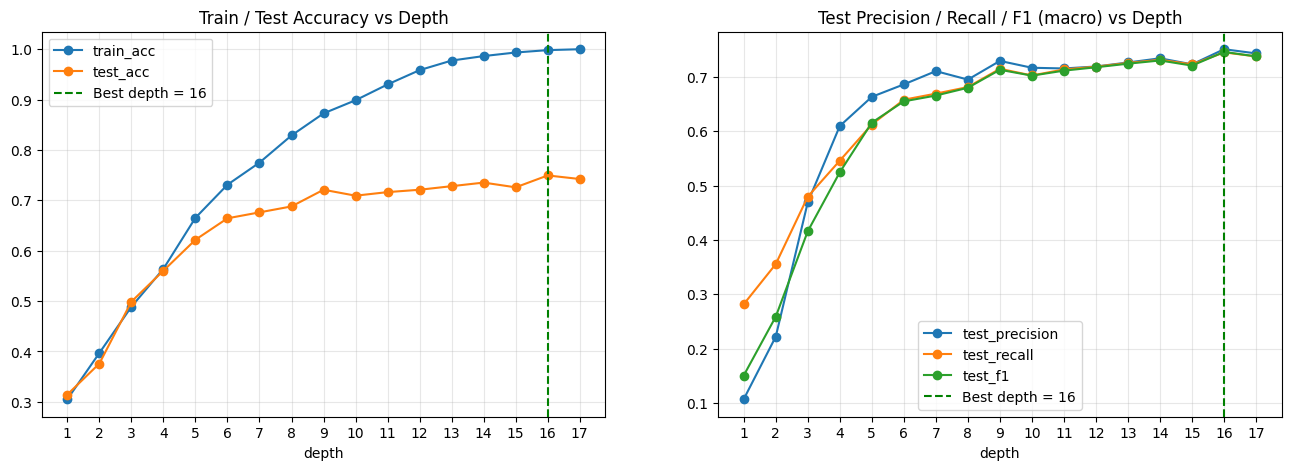

In [ ]:
Xtr, Xte, ytr, yte = split(DROP_COLS)
full = fit(Xtr, ytr)
print("Depth:", full.get_depth(), "| Leaves:", full.get_n_leaves(),
      "| Train acc:", round(full.score(Xtr, ytr), 4), "| Test acc:", round(full.score(Xte, yte), 4))

depth_df = sweep(Xtr, Xte, ytr, yte)
best_depth = depth_df["test_acc"].idxmax()   # smaller depth wins ties
display(depth_df)
print("Best depth:", best_depth, "| Test accuracy:", depth_df.loc[best_depth, "test_acc"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
depth_df[["train_acc", "test_acc"]].plot(marker="o", ax=axes[0], title="Train / Test Accuracy vs Depth")
depth_df[["test_precision", "test_recall", "test_f1"]].plot(
    marker="o", ax=axes[1], title="Test Precision / Recall / F1 (macro) vs Depth")
for ax in axes:
    ax.axvline(best_depth, color="green", linestyle="--", label=f"Best depth = {best_depth}")
    ax.set_xticks(depth_df.index); ax.grid(alpha=0.3); ax.legend()
plt.show()

,Train,Test
Accuracy,0.9982,0.7494
Precision (macro),0.9982,0.7508
Recall (macro),0.9984,0.7450
F1 (macro),0.9983,0.7458


                     precision    recall  f1-score   support

Insufficient_Weight     0.7759    0.8333    0.8036        54
      Normal_Weight     0.5926    0.5517    0.5714        58
     Obesity_Type_I     0.6279    0.7714    0.6923        70
    Obesity_Type_II     0.9107    0.8500    0.8793        60
   Obesity_Type_III     0.9697    0.9846    0.9771        65
 Overweight_Level_I     0.6923    0.6207    0.6545        58
Overweight_Level_II     0.6863    0.6034    0.6422        58

           accuracy                         0.7494       423
          macro avg     0.7508    0.7450    0.7458       423
       weighted avg     0.7514    0.7494    0.7482       423



,Predicted: Insufficient_Weight,Predicted: Normal_Weight,Predicted: Obesity_Type_I,Predicted: Obesity_Type_II,Predicted: Obesity_Type_III,Predicted: Overweight_Level_I,Predicted: Overweight_Level_II
Actual: Insufficient_Weight,45,5,0,0,1,0,3
Actual: Normal_Weight,6,32,11,0,0,4,5
Actual: Obesity_Type_I,1,5,54,3,0,4,3
Actual: Obesity_Type_II,0,1,1,51,0,4,3
Actual: Obesity_Type_III,0,1,0,0,64,0,0
Actual: Overweight_Level_I,4,5,8,2,1,36,2
Actual: Overweight_Level_II,2,5,12,0,0,4,35


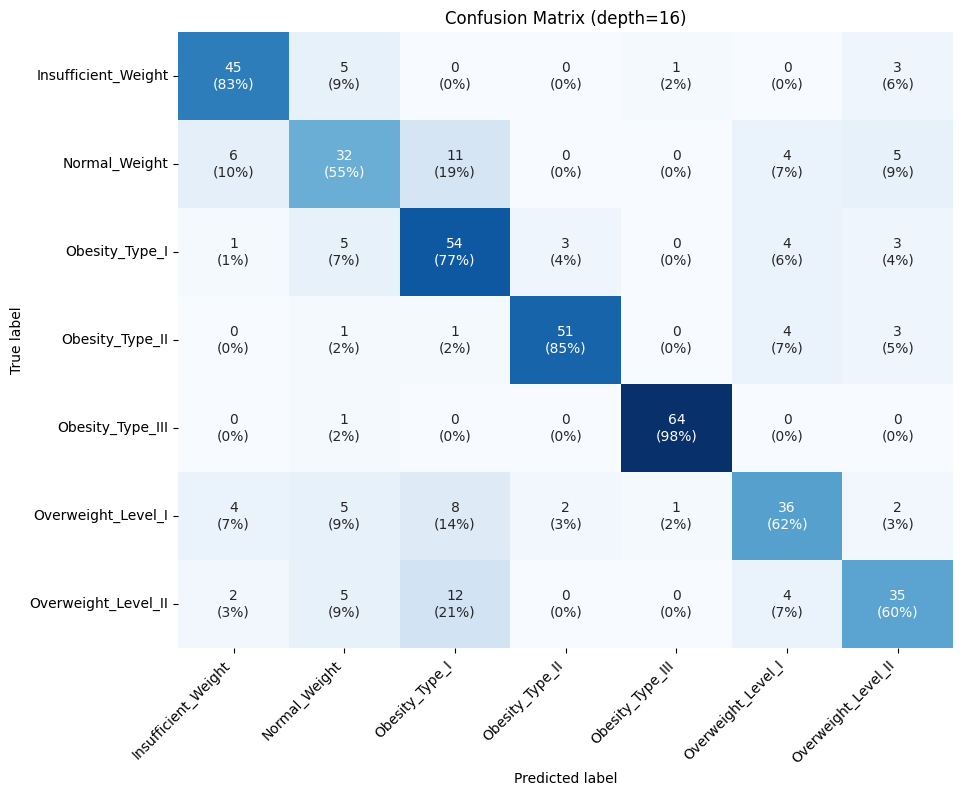

,0
Age,0.1684
TUE,0.1560
FCVC,0.1478
FAF,0.0867
NCP,0.0717
CH2O,0.0706
Gender_Female,0.0429
CALC_Sometimes,0.0400
family_history_with_overweight_yes,0.0348
CAEC_Frequently,0.0346


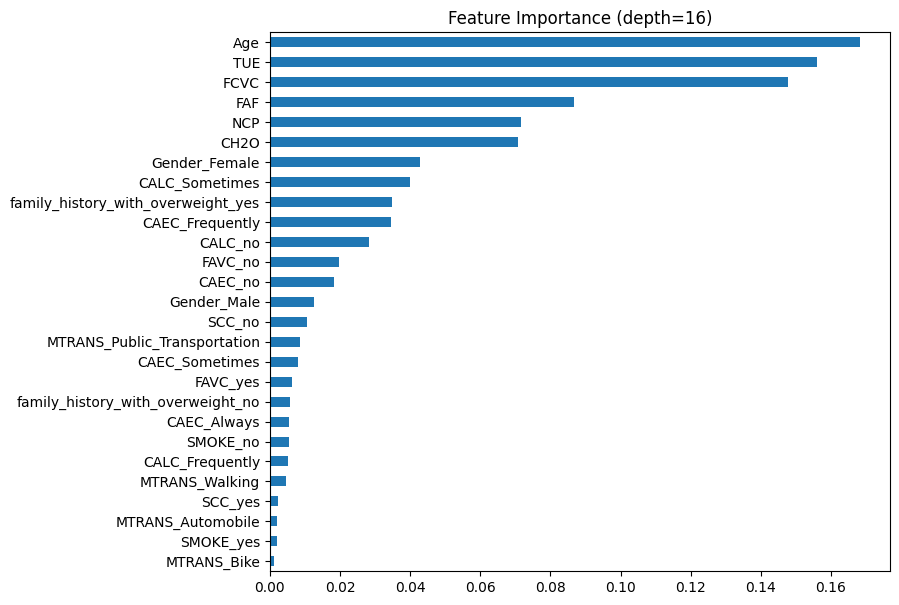

'tree_final.png'

In [ ]:
best = fit(Xtr, ytr, max_depth=best_depth)
labels = best.classes_
display(pd.DataFrame({"Train": scores(ytr, best.predict(Xtr)), "Test": scores(yte, best.predict(Xte))},
                     index=["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]).round(4))
evaluate(best, Xte, yte, f"Confusion Matrix (depth={best_depth})", pct=True)

# Feature importance (only features used by the tree)
imp = pd.Series(best.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
imp = imp[imp > 0]
display(imp.round(4))
imp.sort_values().plot.barh(figsize=(8, 7), title=f"Feature Importance (depth={best_depth})")
plt.show()

# Tree plot: conditions in internal nodes, only the class in leaves
t, colors = best.tree_, plt.cm.Set3(np.linspace(0, 1, len(labels)))
g = Digraph(graph_attr={"dpi": "100"}, node_attr={"shape": "box", "fontname": "Helvetica"})
for n in range(t.node_count):
    if t.children_left[n] == t.children_right[n]:
        k = t.value[n][0].argmax()
        g.node(str(n), labels[k], style="filled", fillcolor=to_hex(colors[k]))
    else:
        g.node(str(n), f"{Xtr.columns[t.feature[n]]} <= {t.threshold[n]:.2f}")
        g.edge(str(n), str(t.children_left[n]), "True")
        g.edge(str(n), str(t.children_right[n]), "False")
g.render("tree_final", format="pdf", cleanup=True)
g.render("tree_final", format="png", cleanup=True)

,train_acc,test_acc,test_precision,test_recall,test_f1
depth,,,,,
1,0.2909,0.2908,0.0938,0.2857,0.1378
2,0.5539,0.5390,0.3724,0.5491,0.4272
3,0.6487,0.6643,0.6115,0.6509,0.6159
4,0.7879,0.7754,0.7821,0.7756,0.7757
5,0.8507,0.8109,0.8214,0.8052,0.8095
6,0.9088,0.8723,0.8872,0.8674,0.8697
7,0.9414,0.8700,0.8741,0.8644,0.8668
8,0.9828,0.9149,0.9163,0.9126,0.9137
9,0.9935,0.9149,0.9158,0.9123,0.9135


=== Summary at best depth ===


,best_depth,train_acc,test_acc,test_precision,test_recall,test_f1
Without Height/Weight,16,0.9982,0.7494,0.7508,0.7450,0.7458
With Height/Weight,10,0.9982,0.9173,0.9179,0.9151,0.9160


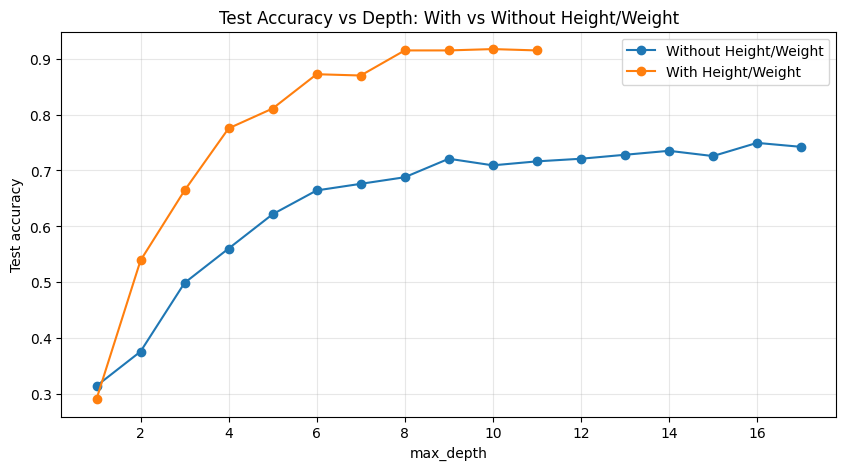

                     precision    recall  f1-score   support

Insufficient_Weight     0.9592    0.8704    0.9126        54
      Normal_Weight     0.8065    0.8621    0.8333        58
     Obesity_Type_I     0.9155    0.9286    0.9220        70
    Obesity_Type_II     0.9667    0.9667    0.9667        60
   Obesity_Type_III     1.0000    0.9846    0.9922        65
 Overweight_Level_I     0.8793    0.8793    0.8793        58
Overweight_Level_II     0.8983    0.9138    0.9060        58

           accuracy                         0.9173       423
          macro avg     0.9179    0.9151    0.9160       423
       weighted avg     0.9190    0.9173    0.9177       423



,Predicted: Insufficient_Weight,Predicted: Normal_Weight,Predicted: Obesity_Type_I,Predicted: Obesity_Type_II,Predicted: Obesity_Type_III,Predicted: Overweight_Level_I,Predicted: Overweight_Level_II
Actual: Insufficient_Weight,47,7,0,0,0,0,0
Actual: Normal_Weight,2,50,0,0,0,6,0
Actual: Obesity_Type_I,0,0,65,1,0,0,4
Actual: Obesity_Type_II,0,0,2,58,0,0,0
Actual: Obesity_Type_III,0,0,0,1,64,0,0
Actual: Overweight_Level_I,0,5,0,0,0,51,2
Actual: Overweight_Level_II,0,0,4,0,0,1,53


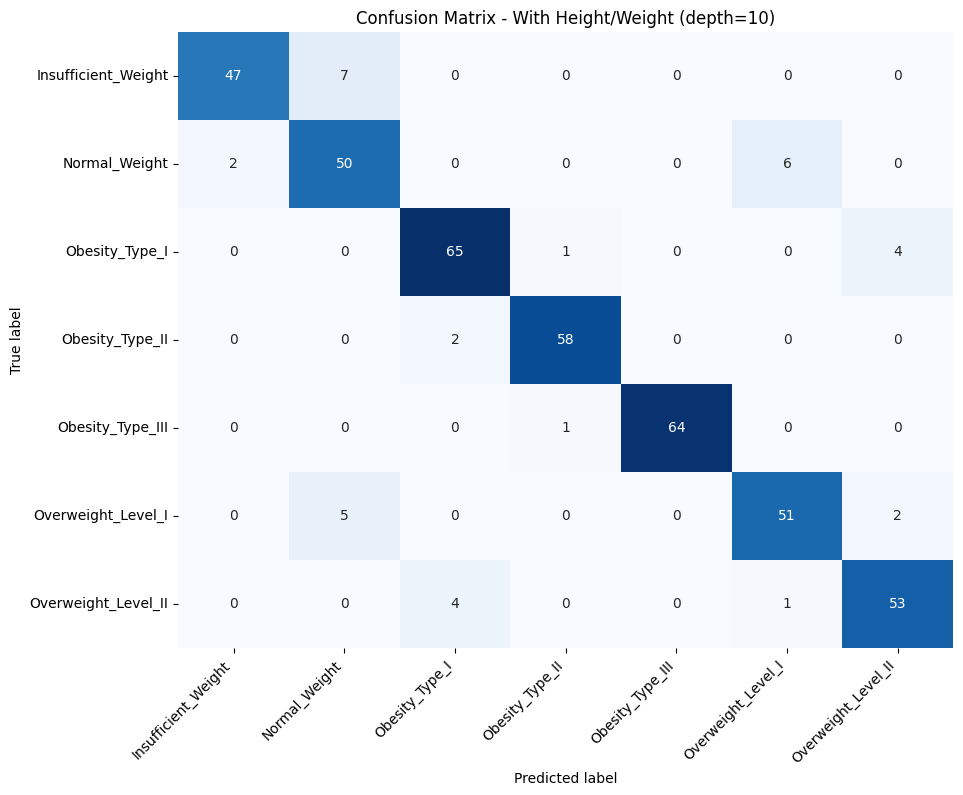

,0
Weight,0.4755
Height,0.2237
Gender_Male,0.1589
Age,0.0395
CALC_no,0.0246
FAVC_no,0.0218
FCVC,0.0167
TUE,0.0127
CAEC_Sometimes,0.0069
NCP,0.0065


In [ ]:
Xtr2, Xte2, ytr2, yte2 = split([])
df_with = sweep(Xtr2, Xte2, ytr2, yte2)
bd = df_with["test_acc"].idxmax()
display(df_with)

summary = pd.DataFrame({"Without Height/Weight": depth_df.loc[best_depth],
                        "With Height/Weight": df_with.loc[bd]}).T
summary.insert(0, "best_depth", [best_depth, bd])
print("=== Summary at best depth ===")
display(summary)

plt.figure(figsize=(10, 5))
for name, d in {"Without Height/Weight": depth_df, "With Height/Weight": df_with}.items():
    plt.plot(d.index, d["test_acc"], marker="o", label=name)
plt.xlabel("max_depth"); plt.ylabel("Test accuracy")
plt.title("Test Accuracy vs Depth: With vs Without Height/Weight")
plt.grid(alpha=0.3); plt.legend(); plt.show()

m = fit(Xtr2, ytr2, max_depth=bd)
evaluate(m, Xte2, yte2, f"Confusion Matrix - With Height/Weight (depth={bd})")
imp = pd.Series(m.feature_importances_, index=Xtr2.columns).sort_values(ascending=False)
display(imp[imp > 0].head(10).round(4))